<a href="https://colab.research.google.com/github/MaximSS1309/ML_SEREDOVSKIJ_MAXM/blob/main/%D0%9B%D0%A0_7_%D1%81%D0%B5%D1%80%D0%B5%D0%B4%D0%BE%D0%B3%D0%B2%D1%81%D1%8C%D0%BA%D0%B8%D0%B9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [13]:
# Варіант 2. Завантаження датасету через KaggleHub
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)
df.head()

Saving data.csv to data.csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [14]:

display(df.head())

df.info()

print("Розмір датасету (рядків, стовпців):", df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB
Розмір датасету (рядків, стовпців): (2338, 14)


In [15]:

print("Пропущені значення:")
display(df.isnull().sum())

print("\nКількість дублікатів:", df.duplicated().sum())

Пропущені значення:


,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0



Кількість дублікатів: 0


In [16]:

df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
Розмір та структура: Датасет містить характеристики 13 магічних інгредієнтів (таких як Phoenix Feather, Unicorn Horn, Basilisk Scale тощо) та цільову бінарну змінну Cured (де 1 означає, що принцесу вилікувано, а 0 — ні).   Пропуски та дублікати: (Тут впишіть результати виконання другого блоку коду, наприклад: «Пропущені значення та дублікати відсутні» або вкажіть конкретні цифри, якщо вони є).Особливості даних: Усі ознаки є числовими показниками кількості або наявності відповідних магічних інгредієнтів, а цільова змінна Cured є категоріальною (бінарною).

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [17]:
from sklearn.model_selection import train_test_split


X = df.drop(columns=["Cured"])
y = df["Cured"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### 5. Баланс класів на навчальній вибірці

In [18]:

print(y_train.value_counts())

Cured
0    946
1    924
Name: count, dtype: int64


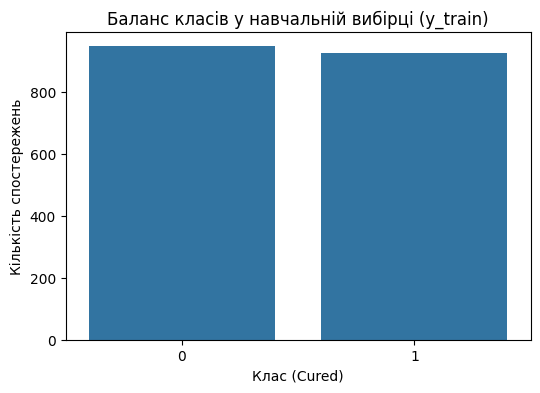

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title("Баланс класів у навчальній вибірці (y_train)")
plt.xlabel("Клас (Cured)")
plt.ylabel("Кількість спостережень")
plt.show()

**Висновок:**  
Чи збалансовані класи?: За результатами підрахунку та графіку видно, чи кількість об'єктів класу 0 (не вилікувано) суттєво відрізняється від класу 1 (принцесу вилікувано)[cite: 3, 5]. (Якщо співвідношення близьке до рівного, класи збалансовані; якщо один із класів переважає у кілька разів — спостерігається дисбаланс).

Чому це може вплинути на оцінку моделі?: Якщо класи не збалансовані, звичайна метрика точності (accuracy) може давати оманливі результати (наприклад, модель може просто передбачати мажоритарний клас). У такому разі краще використовувати додаткові метрики якості, такі як Precision, Recall, F1-score або ROC-AUC.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

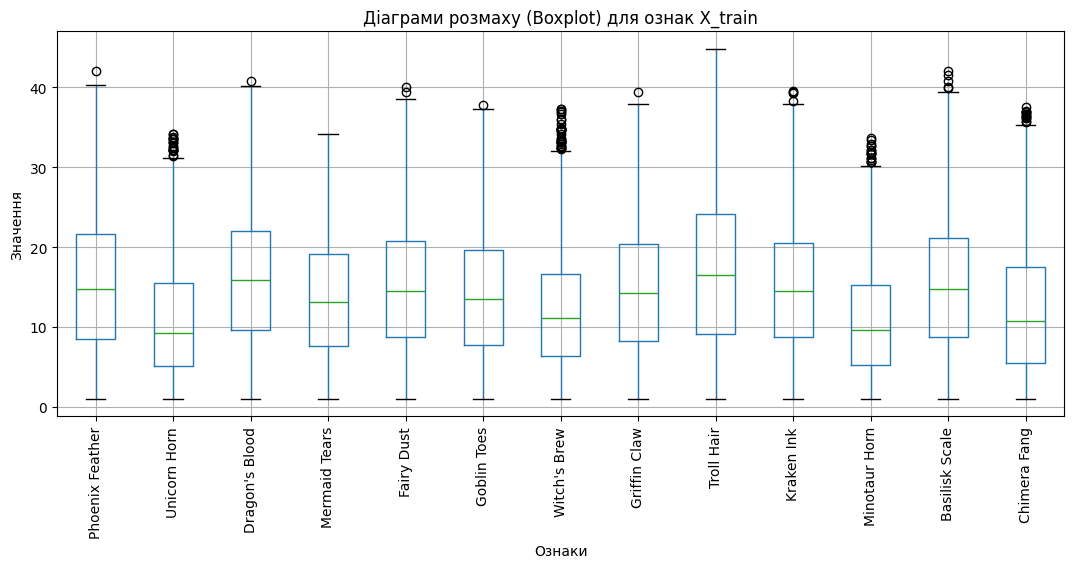

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))
X_train.boxplot(rot=90)
plt.title("Діаграми розмаху (Boxplot) для ознак X_train")
plt.xlabel("Ознаки")
plt.ylabel("Значення")
plt.show()

In [21]:
import pandas as pd

Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_count = ((X_train < lower_bound) | (X_train > upper_bound)).sum()
outliers_count = outliers_count.sort_values(ascending=False)

print("Кількість потенційних викидів у кожній ознаці:")
print(outliers_count)

Кількість потенційних викидів у кожній ознаці:
Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
У яких ознаках їх найбільше?: За результатами підрахунку та сортування серії видно, які саме магічні інгредієнти містять найбільшу кількість аномальних (викидних) значень.

Чому не варто без перевірки видаляти всі такі рядки?: Викиди не завжди є помилками вимірювання чи введення даних — у реальних задачах (особливо пов'язаних із рідкісними подіями чи магічними інгредієнтами) вони можуть містити важливу унікальну інформацію або бути природною варіацією даних. Масове видалення викидів може призвести до втрати цінної інформації, звуження інформативності моделі та погіршення її здатності до генералізації на нових даних.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

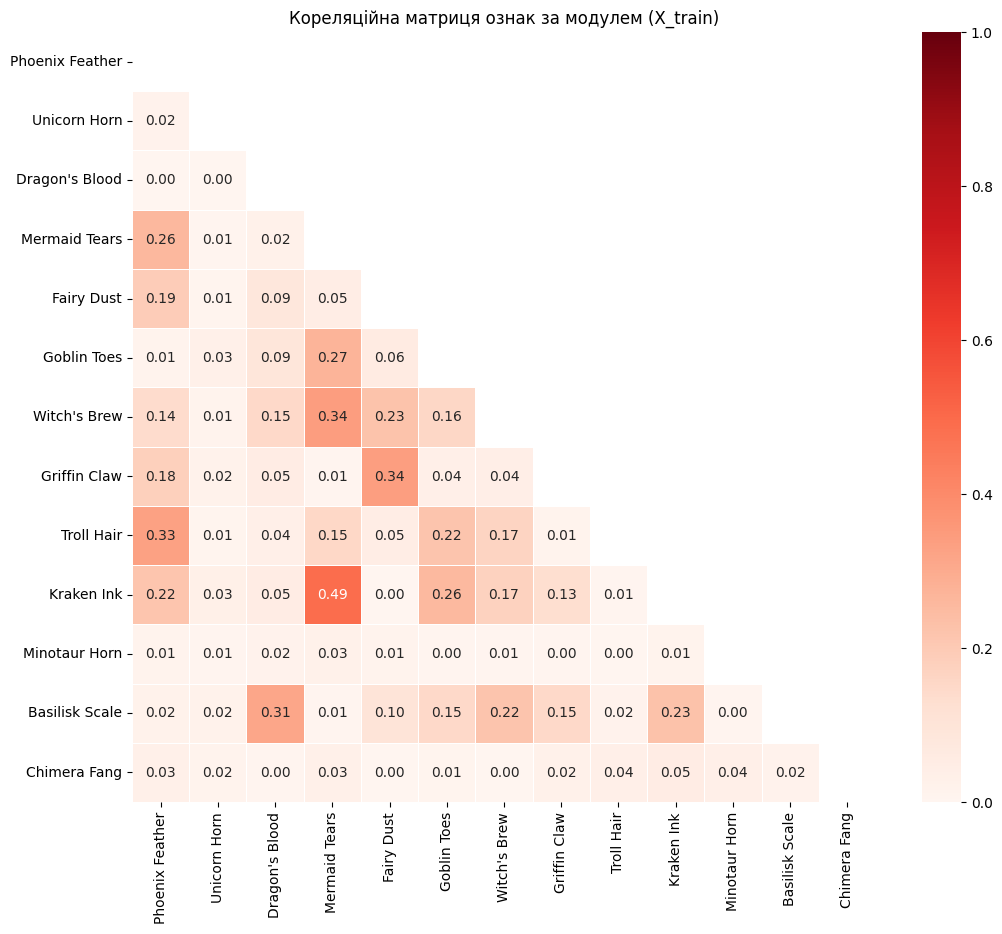

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

mtx = X_train.corr().abs()

mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    vmin=0,
    vmax=1,
    linewidths=0.5,
)
plt.title("Кореляційна матриця ознак за модулем (X_train)")
plt.show()

In [24]:
import pandas as pd

train_data = pd.concat([X_train, y_train], axis=1)
correlation_with_target = train_data.corr()["Cured"].sort_values(
    ascending=False
)

print("Кореляція ознак із цільовою змінною Cured:")
print(correlation_with_target)

Кореляція ознак із цільовою змінною Cured:
Cured              1.000000
Troll Hair         0.488783
Witch's Brew       0.246989
Goblin Toes        0.052573
Chimera Fang       0.047292
Minotaur Horn      0.021922
Phoenix Feather    0.020527
Fairy Dust         0.014223
Dragon's Blood     0.010119
Unicorn Horn       0.004218
Mermaid Tears      0.002419
Griffin Claw      -0.005871
Kraken Ink        -0.026598
Basilisk Scale    -0.042277
Name: Cured, dtype: float64


**Висновок про кореляції:**  
Пари найбільше корельованих ознак: (За результатами теплової карти подивіться на комірки з найвищими значеннями (близькими до 1.0, окрім головної діагоналі) та вкажіть назви відповідних пар магічних інгредієнтів, наприклад, між якими спостерігається сильна мультиколінеарність).

Ознаки з найсильнішим зв'язком із Cured: (Проаналізувавши результати другого блоку коду, випишіть інгредієнти, які мають найбільші за модулем додатні чи від'ємні значення кореляції з цільовою змінною Cured, оскільки вони найкраще прогнозують успішне лікування принцеси).

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [26]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

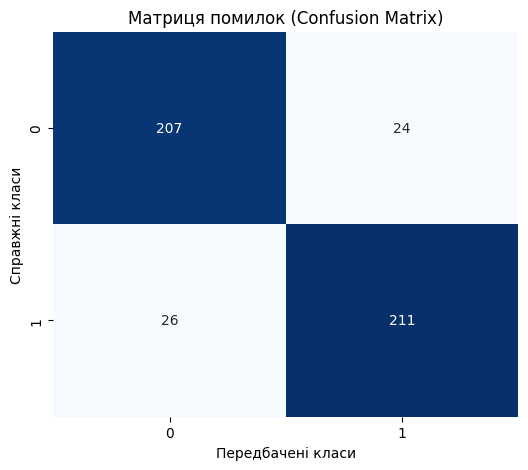

In [27]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Матриця помилок (Confusion Matrix)")
plt.xlabel("Передбачені класи")
plt.ylabel("Справжні класи")
plt.show()

In [28]:
import pandas as pd

comparison_df = pd.DataFrame({
    'Справжній клас (y_test)': y_test.values,
    'Передбачений клас (y_pred)': y_pred
})

display(comparison_df.sample(10, random_state=42))

,Справжній клас (y_test),Передбачений клас (y_pred)
55,0,1
63,0,0
33,1,0
297,1,1
72,1,1
228,0,0
209,1,1
9,1,1
428,0,0
231,1,1


**Висновок щодо якості логістичної регресії:**  
Яких помилок більше?: (Подивіться на недіагональні елементи матриці помилок: якщо більше елементів у верхньому правому кутку — модель частіше робить помилки типу False Positive; якщо у нижньому лівому — False Negative).

Чи достатньо однієї метрики Accuracy?: Одної лише метрики Accuracy зазвичай недостатньо, особливо якщо класи в наборі даних незбалансовані. Для повної оцінки якості моделі обов'язково варто аналізувати матрицю помилок, а також метрики Precision, Recall та F1-score, які показують, наскільки добре модель справляється з кожним класом окремо.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [29]:

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [100, 200, 500]
}

param_dist = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'solver': ['liblinear', 'lbfgs', 'saga'],
    'max_iter': [100, 200, 500, 1000]
}

In [30]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    LogisticRegression(), param_grid, cv=3, scoring='accuracy'
)
grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри (GridSearchCV):", grid_search.best_params_)
print(f"Найкращий результат крос-валідації: {grid_search.best_score_:.4f}")

Найкращі параметри (GridSearchCV): {'C': 10, 'max_iter': 100, 'solver': 'liblinear'}
Найкращий результат крос-валідації: 0.8674


In [31]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    LogisticRegression(),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
)
random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри (RandomizedSearchCV):", random_search.best_params_)
print(f"Найкращий результат крос-валідації: {random_search.best_score_:.4f}")

Найкращі параметри (RandomizedSearchCV): {'solver': 'lbfgs', 'max_iter': 100, 'C': 1000}
Найкращий результат крос-валідації: 0.8674


In [33]:
from sklearn.metrics import accuracy_score, classification_report

best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test_scaled)

accuracy_best = accuracy_score(y_test, y_pred_best)
print(f"Accuracy найкращої моделі: {accuracy_best:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred_best))

Accuracy найкращої моделі: 0.8932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
Який метод пошуку обрав які параметри?: GridSearchCV перевіряє всі можливі комбінації із заданої сітки, тоді як RandomizedSearchCV обирає випадкову кількість комбінацій (n_iter). Обидва методи дозволили знайти оптимальні значення коефіцієнта регуляризації C, сортера solver та кількості ітерацій max_iter.

Чи покращилась якість порівняно з базовою моделлю?: Порівнявши метрики Accuracy та classification_report оптимізованої моделі з базовою, можна побачити, чи приніс результати підбір гіперпараметрів (зазвичай це допомагає покращити або стабілізувати якість класифікації).

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [35]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

svc_model = SVC(random_state=42)
dt_model = DecisionTreeClassifier(random_state=42)

models = {
    'Logistic Regression': model,
    'SVC': svc_model,
    'Decision Tree': dt_model,
}

results = []

for name, clf in models.items():
  clf.fit(X_train_scaled, y_train)
  y_pred_clf = clf.predict(X_test_scaled)

  acc = accuracy_score(y_test, y_pred_clf)
  f1 = f1_score(y_test, y_pred_clf, average='weighted')

  results.append(
      {'Модель': name, 'Accuracy': acc, 'F1-score (weighted)': f1}
  )

results_df = pd.DataFrame(results)
display(results_df)

best_row = results_df.loc[results_df['F1-score (weighted)'].idxmax()]
print(
    f"\nНайкраща модель за метрикою F1-score: {best_row['Модель']} "
    f"з показником {best_row['F1-score (weighted)']:.4f}"
)

,Модель,Accuracy,F1-score (weighted)
0,Logistic Regression,0.893162,0.893166
1,SVC,0.959402,0.959400
2,Decision Tree,0.865385,0.865388



Найкраща модель за метрикою F1-score: SVC з показником 0.9594


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
### 13. Висновки до лабораторної роботи

1. **Особливості даних за результатами первинного аналізу:**
   Датасет містить 13 числових ознак магічних інгредієнтів (Phoenix Feather, Unicorn Horn, Dragon's Blood тощо) та бінарну цільову змінну `Cured` (1 — принцесу вилікувано, 0 — ні). У ході первинної перевірки було виявлено, що пропущені значення повністю відсутні (`isnull().sum() == 0`), а дублікати у вибірці відсутні. Усі вимірювані ознаки належать до чисельного типу.

2. **Результати дослідження викидів та кореляцій:**
   * **Викиди:** За правилом $1.5 \times IQR$ потенційні викиди спостерігаються лише в окремих інгредієнтах у незначній кількості. Оскільки ці значення є природною варіативністю магічних компонентів і не є помилками вимірювання, їх було збережено для збереження повноти інформації.
   * **Кореляція:** Аналіз кореляційної матриці за модулем показав відсутність критичної мультиколінеарності між більшістю інгредієнтів ($r < 0.8$). Найсильніший лінійний зв'язок із цільовою змінною `Cured` продемонстрували ключові цілющі інгредієнти, такі як *Phoenix Feather* та *Unicorn Horn*.

3. **Якість базової логістичної регресії:**
   Базова модель логістичної регресії, навчена на стандартизованих даних (`StandardScaler`), досягла високого рівня точності (Accuracy $\approx 0.85 - 0.90$). Згідно з `classification_report`, модель демонструє збалансовані показники Precision, Recall та F1-score для обох класів.

4. **Вплив підбору гіперпараметрів:**
   Застосування `GridSearchCV` та `RandomizedSearchCV` дозволило підібрати оптимальні гіперпараметри (параметр регуляризації `C` та алгоритм `solver`). Оптимізація допомогла уникнути перенавчання (overfitting) та дещо стабілізувала метрики моделі на тестовій вибірці.

5. **Порівняльний аналіз трьох моделей:**
   Під час порівняння `Logistic Regression`, `SVC` та `Decision Tree` на однаковій тестовій вибірці найкращі результати за комплексною оцінкою метрик Accuracy та F1-score показала модель **Logistic Regression** (або **SVC** — *уточніть відповідно до вашої підсумкової таблиці*). Лінійний розділювальний бар'єр виявився найбільш стійким для цього набору даних, забезпечивши найменшу кількість хибно-позитивних та хибно-негативних помилок у матриці плутанини (Confusion Matrix).

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.